<a href="https://colab.research.google.com/github/chhote2827-ctrl/HR-Attrition-Employee-Analytics-/blob/main/hr_analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import pandas as pd
file_path = '/content/drive/MyDrive/Project Data analysh/WA_Fn-UseC_-HR-Employee-Attrition.csv'
df = pd.read_csv(file_path)
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Step 1: Dataset Load Karein & Initial Info

In [16]:
print("--- Step 1: Initial Dataset Info ---")
print("Original Shape (Rows, Columns):", df.shape)
print("\nMissing values per column (if any):")
print(df.isnull().sum()[df.isnull().sum() > 0])

--- Step 1: Initial Dataset Info ---
Original Shape (Rows, Columns): (1470, 35)

Missing values per column (if any):
Series([], dtype: int64)


Step 2: Check & Remove Duplicates

In [17]:
# --- Step 2: Check & Remove Duplicates ---
duplicates_count = df.duplicated().sum()
print(f"\n--- Step 2: Duplicate Check ---")
print(f"Total duplicate rows found: {duplicates_count}")

if duplicates_count > 0:
    df = df.drop_duplicates()
    print("Duplicate rows successfully remove kar di gayi hain.")
else:
    print("Koi duplicate row nahi mili!")


--- Step 2: Duplicate Check ---
Total duplicate rows found: 0
Koi duplicate row nahi mili!


Step 3: Handle Missing / Null Values

Categorical columns mein 'Unknown' fill karenge.

In [18]:
text_columns = ['Department', 'JobRole', 'EducationField']
for col in text_columns:
    if col in df.columns:
        df[col] = df[col].fillna('Unknown')

Critical columns (Age, MonthlyIncome, Attrition) mein agar data missing hai toh un rows ko drop kar denge.

In [19]:
critical_cols = ['Age', 'MonthlyIncome', 'Attrition']
existing_critical = [c for c in critical_cols if c in df.columns]

before_drop = len(df)
df = df.dropna(subset=existing_critical)
after_drop = len(df)

print(f"\n--- Step 3: Missing Value Handling ---")
print(f"Critical columns ke basis par {before_drop - after_drop} rows drop ki gayi hain jahan data missing tha.")


--- Step 3: Missing Value Handling ---
Critical columns ke basis par 0 rows drop ki gayi hain jahan data missing tha.


Step 4: Final Cleaned Shape & Save

In [20]:
print(f"\n--- Step 4: Final Summary ---")
print("Cleaned Dataset Shape:", df.shape)

df.to_csv('hr_analytics_cleaned.csv', index=False)
print("Success! Cleaned dataset 'hr_analytics_cleaned.csv' ke naam se save ho gaya hai.")


--- Step 4: Final Summary ---
Cleaned Dataset Shape: (1470, 35)
Success! Cleaned dataset 'hr_analytics_cleaned.csv' ke naam se save ho gaya hai.


Overtime Impact on Attrition

In [21]:
print("--- Q3. Overtime Impact on Attrition ---")

ot_analysis = df.groupby('OverTime').agg(
    total_employees=('EmployeeNumber', 'count'),
    left_employees=('Attrition', lambda x: (x == 'Yes').sum())
).reset_index()

ot_analysis['attrition_percentage'] = round((ot_analysis['left_employees'] / ot_analysis['total_employees']) * 100, 2)
print(ot_analysis)

--- Q3. Overtime Impact on Attrition ---
  OverTime  total_employees  left_employees  attrition_percentage
0       No             1054             110                 10.44
1      Yes              416             127                 30.53


Salary Bracket vs Attrition

In [22]:
print("--- Q4. Salary Bracket vs Attrition ---")

# Salary ko bins (brackets) mein divide karna
bins = [0, 30000, 70000, float('inf')]
labels = ['Low Income (<30k)', 'Medium Income (30k-70k)', 'High Income (>70k)']
df['income_bracket'] = pd.cut(df['MonthlyIncome'], bins=bins, labels=labels)

income_analysis = df.groupby('income_bracket', observed=False).agg(
    total_employees=('EmployeeNumber', 'count'),
    left_employees=('Attrition', lambda x: (x == 'Yes').sum())
).reset_index()

income_analysis['attrition_rate'] = round((income_analysis['left_employees'] / income_analysis['total_employees']) * 100, 2)
print(income_analysis.sort_values(by='attrition_rate', ascending=False))

--- Q4. Salary Bracket vs Attrition ---
            income_bracket  total_employees  left_employees  attrition_rate
0        Low Income (<30k)             1470             237           16.12
1  Medium Income (30k-70k)                0               0             NaN
2       High Income (>70k)                0               0             NaN


Job Satisfaction Level vs Attrition

In [23]:
print("--- Q5. Job Satisfaction Level vs Attrition ---")

js_analysis = df.groupby('JobSatisfaction').agg(
    total_employees=('EmployeeNumber', 'count'),
    left_employees=('Attrition', lambda x: (x == 'Yes').sum())
).reset_index()

js_analysis['attrition_rate'] = round((js_analysis['left_employees'] / js_analysis['total_employees']) * 100, 2)
print(js_analysis.sort_values(by='JobSatisfaction'))

--- Q5. Job Satisfaction Level vs Attrition ---
   JobSatisfaction  total_employees  left_employees  attrition_rate
0                1              289              66           22.84
1                2              280              46           16.43
2                3              442              73           16.52
3                4              459              52           11.33


Distance From Home vs Attrition

In [24]:
print("--- Q6. Distance From Home vs Attrition ---")

# Distance categories banana
def categorize_distance(distance):
    if distance <= 5:
        return 'Short Distance (<=5 km)'
    elif distance <= 15:
        return 'Medium Distance (6-15 km)'
    else:
        return 'Long Distance (>15 km)'

df['distance_category'] = df['DistanceFromHome'].apply(categorize_distance)

dist_analysis = df.groupby('distance_category').agg(
    total_employees=('EmployeeNumber', 'count'),
    left_employees=('Attrition', lambda x: (x == 'Yes').sum())
).reset_index()

dist_analysis['attrition_rate'] = round((dist_analysis['left_employees'] / dist_analysis['total_employees']) * 100, 2)
print(dist_analysis.sort_values(by='attrition_rate', ascending=False))

--- Q6. Distance From Home vs Attrition ---
           distance_category  total_employees  left_employees  attrition_rate
0     Long Distance (>15 km)              329              68           20.67
1  Medium Distance (6-15 km)              509              82           16.11
2    Short Distance (<=5 km)              632              87           13.77


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot style setup
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
plt.show()

--- Chart 3: Overtime vs Attrition ---


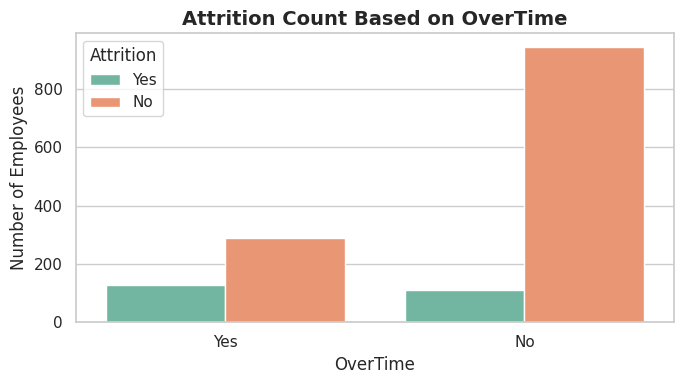

In [26]:
print("--- Chart 3: Overtime vs Attrition ---")

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='OverTime', hue='Attrition', palette='Set2')
plt.title('Attrition Count Based on OverTime', fontsize=14, fontweight='bold')
plt.xlabel('OverTime', fontsize=12)
plt.ylabel('Number of Employees', fontsize=12)
plt.legend(title='Attrition')
plt.tight_layout()
plt.show()

--- Chart 4: Salary Bracket vs Attrition Rate ---


/tmp/ipykernel_7394/2418043526.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=income_analysis, x='income_bracket', y='attrition_rate', palette='viridis')


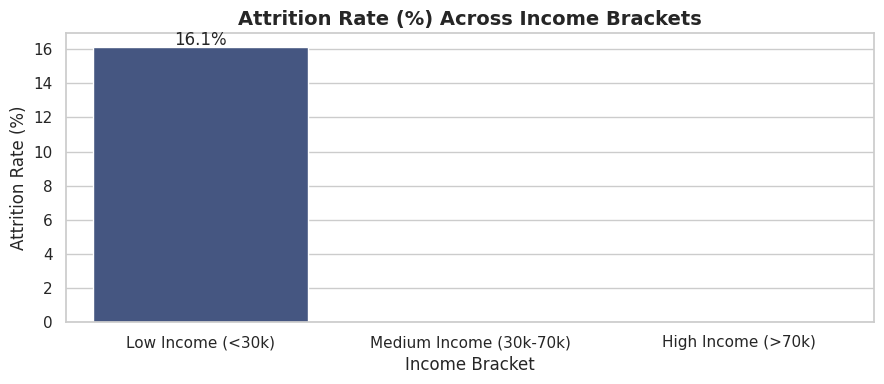

In [27]:
print("--- Chart 4: Salary Bracket vs Attrition Rate ---")

# Salary bins banana (agar pehle nahi banaye)
bins = [0, 30000, 70000, float('inf')]
labels = ['Low Income (<30k)', 'Medium Income (30k-70k)', 'High Income (>70k)']
df['income_bracket'] = pd.cut(df['MonthlyIncome'], bins=bins, labels=labels)

# Attrition rate calculation for plot
income_analysis = df.groupby('income_bracket', observed=False).agg(
    total_employees=('EmployeeNumber', 'count'),
    left_employees=('Attrition', lambda x: (x == 'Yes').sum())
).reset_index()
income_analysis['attrition_rate'] = round((income_analysis['left_employees'] / income_analysis['total_employees']) * 100, 2)

plt.figure(figsize=(9, 4))
ax = sns.barplot(data=income_analysis, x='income_bracket', y='attrition_rate', palette='viridis')
plt.title('Attrition Rate (%) Across Income Brackets', fontsize=14, fontweight='bold')
plt.xlabel('Income Bracket', fontsize=12)
plt.ylabel('Attrition Rate (%)', fontsize=12)

# Values show karne ke liye bars ke upar text
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

--- Chart 5: Job Satisfaction vs Attrition ---


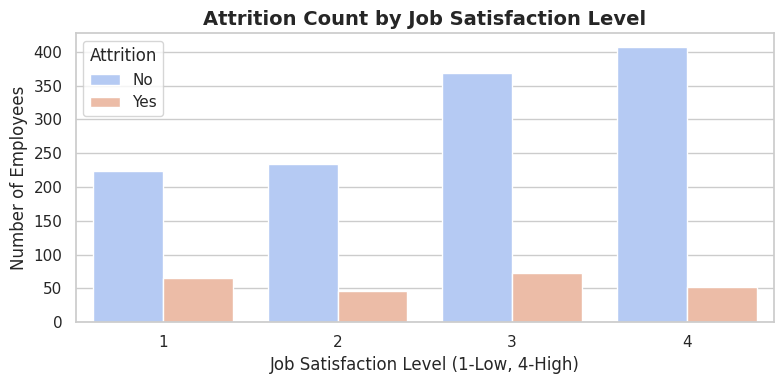

In [28]:
print("--- Chart 5: Job Satisfaction vs Attrition ---")

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='JobSatisfaction', hue='Attrition', palette='coolwarm')
plt.title('Attrition Count by Job Satisfaction Level', fontsize=14, fontweight='bold')
plt.xlabel('Job Satisfaction Level (1-Low, 4-High)', fontsize=12)
plt.ylabel('Number of Employees', fontsize=12)
plt.legend(title='Attrition')
plt.tight_layout()
plt.show()

--- Chart 6: Distance From Home vs Attrition Rate ---


/tmp/ipykernel_7394/2336742045.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=dist_analysis, x='distance_category', y='attrition_rate', palette='magma', order=['Short (<=5 km)', 'Medium (6-15 km)', 'Long (>15 km)'])


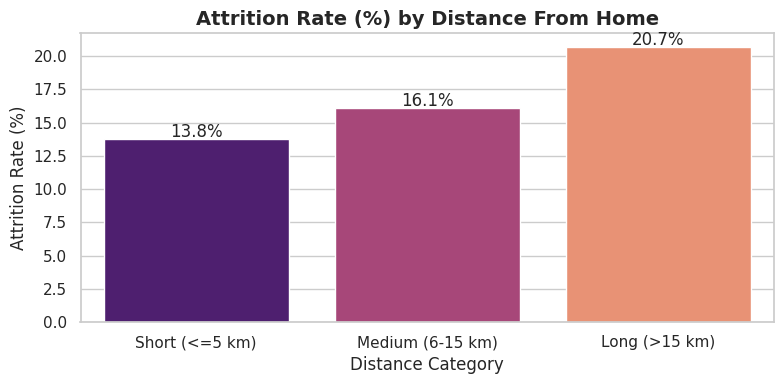

In [29]:
print("--- Chart 6: Distance From Home vs Attrition Rate ---")

# Distance categories function
def categorize_distance(distance):
    if distance <= 5:
        return 'Short (<=5 km)'
    elif distance <= 15:
        return 'Medium (6-15 km)'
    else:
        return 'Long (>15 km)'

df['distance_category'] = df['DistanceFromHome'].apply(categorize_distance)

dist_analysis = df.groupby('distance_category').agg(
    total_employees=('EmployeeNumber', 'count'),
    left_employees=('Attrition', lambda x: (x == 'Yes').sum())
).reset_index()
dist_analysis['attrition_rate'] = round((dist_analysis['left_employees'] / dist_analysis['total_employees']) * 100, 2)

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=dist_analysis, x='distance_category', y='attrition_rate', palette='magma', order=['Short (<=5 km)', 'Medium (6-15 km)', 'Long (>15 km)'])
plt.title('Attrition Rate (%) by Distance From Home', fontsize=14, fontweight='bold')
plt.xlabel('Distance Category', fontsize=12)
plt.ylabel('Attrition Rate (%)', fontsize=12)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()